<!-- d2l:prose id=linear-regression-concise-md-1 fw=all -->

# Concise Implementation of Linear Regression

In that section, we built every piece of linear regression from raw tensors: parameter allocation, the affine forward pass, the squared loss, reverse-mode differentiation, the minibatch generator, and the SGD update step. In that section, we organized those components into reusable base classes (`d2l.Module`, `d2l.DataModule`, and `d2l.Trainer`) and verified that `LinearRegressionScratch` trained through `trainer.fit(model, data)` reproduced our benchmark results.

Writing and testing raw parameter tensors and update rules by hand was straightforward for a 3-parameter linear model, but modern architectures like ResNet-50 (that section) or GPT (that section) manage millions to billions of parameters across dozens of layers and train with stateful adaptive optimizers. Deep learning frameworks—PyTorch [@Paszke.Gross.Massa.ea.2019], JAX [@Frostig.Johnson.Leary.2018] (with Flax and Optax), TensorFlow [@Abadi.Barham.Chen.ea.2016], and MXNet [@Chen.Li.Li.ea.2015]—therefore provide hardware-tuned layers, numerically tested loss primitives, and standard optimizers out of the box. In this section, we see how concisely we can express linear regression by plugging those high-level building blocks into `d2l.Module` and `d2l.Trainer`.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=linear-regression-concise-md-2 fw=all -->

## The Fully Connected Layer

In our concise implementation, a subclass `LinearRegression(d2l.Module)` wraps a single built-in fully connected layer with one output unit, initializing its weights from $\mathcal{N}(0, 0.01^2)$ and its bias to zero.

<!-- d2l:prose id=linear-regression-concise-md-3 fw=pytorch -->

PyTorch's `nn.LazyLinear(1)` requires only the output dimension at construction time and infers the number of input features $d$ automatically on the first forward pass.

In [2]:
class LinearRegression(d2l.Module):
    """Linear regression built from framework components."""
    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.LazyLinear(1)

    def weight_init(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, std=0.01)
            nn.init.zeros_(module.bias)

<!-- d2l:prose id=linear-regression-concise-md-4 fw=all -->

Notice that `LinearRegression` does not even need to define `forward`: it
inherits `Module.forward` from that section, which delegates directly
to `self.net(X)`.

## The Loss Function

Instead of writing $(\hat{y} - y)^2 / 2$ by hand, we delegate `loss` to the framework's built-in mean squared error primitive. Standard mean squared error omits the $\frac{1}{2}$ factor of our scratch loss, so it is twice our scratch value and levels off at $\sigma^2 = 10^{-4}$ rather than $\sigma^2 / 2$.

In [3]:
@d2l.add_to_class(LinearRegression)
def loss(self, y_hat, y):
    fn = nn.MSELoss()
    return fn(y_hat, y)

<!-- d2l:prose id=linear-regression-concise-md-5 fw=all -->

## The Optimizer

Similarly, `configure_optimizers` returns the framework's built-in minibatch SGD optimizer, wired to the module's registered parameters and learning rate `self.lr`:

In [4]:
@d2l.add_to_class(LinearRegression)
def configure_optimizers(self):
    return torch.optim.SGD(self.parameters(), self.lr)

<!-- d2l:prose id=linear-regression-concise-md-6 fw=all -->

## Training with Framework Components

With `LinearRegression` defined, training reduces to instantiating the data module, the model (with learning rate $\eta = 0.015$, halved from our scratch rate $\eta = 0.03$ to compensate for the doubled MSE gradient), and `d2l.Trainer(max_epochs=10)`, then calling `trainer.fit(model, data)`:

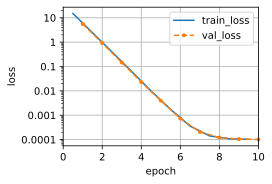

In [5]:
data = d2l.SyntheticRegressionData(w=d2l.tensor([2, -3.4]), b=4.2)
model = LinearRegression(lr=0.015)
model(data.X[:1])  # Creates the parameters of the lazy layer
model.net.apply(model.weight_init)
trainer = d2l.Trainer(max_epochs=10)
trainer.board.yscale = 'log'
trainer.fit(model, data)

In [6]:
print(f"validation loss: {trainer.history['val_loss'][-1]:.2e}")

validation loss: 1.01e-04


<!-- d2l:prose id=linear-regression-concise-md-7 fw=all -->

The final validation loss lands within roughly $3\%$ of the theoretical noise
floor $\sigma^2 = 10^{-4}$, mirroring our from-scratch implementation. Let us add a small helper method `get_w_b` to extract the learned weight tensor and bias from the framework layer and compare them against $(\mathbf{w}^*, b^*)$:

In [7]:
@d2l.add_to_class(LinearRegression)
def get_w_b(self):
    return self.net.weight.detach(), self.net.bias.detach()

In [8]:
w, b = model.get_w_b()
w_error = d2l.numpy(d2l.reshape(w, data.w.shape) - data.w)
b_error = d2l.numpy(b - data.b)
print('error in w:', ', '.join(f'{e:.1e}' for e in w_error))
print('error in b:', ', '.join(f'{e:.1e}' for e in b_error))

error in w: -2.1e-04, 9.5e-04
error in b: -1.1e-03


<!-- d2l:prose id=linear-regression-concise-md-8 fw=all -->

Once again, the errors in $\hat{\mathbf{w}}$ and $\hat{b}$ stay within about a
thousandth, matching our scratch run because the dominant error sources (label
noise across $1{,}000$ examples and the remaining distance after $10$ epochs) are
identical regardless of who wrote the layer.

Everything we checked in the past three sections leaned on knowing the
ground-truth parameters, a luxury we never have on real datasets; in
that section, we tackle how to judge models strictly from
held-out data.

## Summary

Using high-level framework APIs, linear regression reduces to a single dense layer inside a `d2l.Module` subclass that delegates `loss` to built-in mean squared error and `configure_optimizers` to built-in SGD. Because standard mean squared error omits the $\frac{1}{2}$ factor of our scratch objective, both the loss (plateauing at $\sigma^2 = 10^{-4}$) and its gradient double, so halving the learning rate to $\eta = 0.015$ reproduces the parameter updates of our scratch implementation. Because `LinearRegression` satisfies the `d2l.Module` contract, `d2l.Trainer` fits it without a single change to the data pipeline or training loop.

## Exercises

1. [code] **A layer without a bias.** Build `LinearRegression` with a
   layer that has no bias (every framework's dense layer has an argument
   that turns the bias off), and train it as in this section.
    1. Before training, predict the value at which the validation loss
       levels off, using the expected squared error formula from
       that section (accounting for the factor of $2$ in the
       mean squared error). Then check your prediction.
    1. Predict what the weights converge to and how far they end from
       $\mathbf{w}^*$. Since the features have mean zero, the missing bias
       acts on the weights like label noise of standard deviation
       $b^* = 4.2$; it enters both the estimation error of
       that section and the noise
       ball of minibatch SGD (that section). Compare
       your prediction with the errors of the trained weights.

1. [code] **Several outputs.** Change the output width of the layer in
   `LinearRegression` from 1 to 2. After constructing `data`, append to
   `data.y` a second label column
   $y_2 = \mathbf{x}^\top \mathbf{w}_2^* + b_2^* + \epsilon_2$, computed
   from `data.X` with generating parameters of your choice and noise of
   the same size.
    1. Show that the squared loss summed over the two outputs splits into
       two independent linear regressions, one per output. Conclude that
       the parameters learned for one output do not depend on the labels of
       the other.
    1. The framework losses average over every entry of the
       $|\mathcal{B}| \times 2$ matrix of errors of a minibatch
       $\mathcal{B}$, not only over its examples. State by which factor
       the gradient of each output's parameters shrinks relative to the
       single-output model, and which learning rate reproduces the
       single-output training run. Confirm this by training both models
       from the same initial parameters on the same minibatches.

1. [code] **Feature scale and step size.** Multiply the first column of
   `data.X` by 100 after constructing `data`, leaving `data.y` unchanged,
   so that the generating weight of that feature becomes $0.02$. Recall
   from exercise 1 that
   gradient descent diverges once $\eta$ exceeds $2/\mu_{\max}$, where
   $\mu_{\max}$ is the largest eigenvalue of the Hessian $\mathbf{H}$ of
   the loss.
    1. Compute $\mathbf{H}$ for `LinearRegression.loss` and estimate its
       eigenvalues before and after the rescaling.
    1. Predict the largest learning rate for which training does not
       diverge, before and after the rescaling, and check both predictions
       by training at learning rates around them.
    1. At a learning rate just below the new limit, predict how many
       updates the second weight needs to reduce its error by a factor of
       100, and compare the prediction with a measurement. Then standardize
       the rescaled feature as in that section, and show that
       `lr=0.015` works again.

1. [code] **Optimization versus estimation error.** ● Train
   `LinearRegression` with `lr=0.015` and `max_epochs=10` on
   `SyntheticRegressionData` with `num_train` set to each of
   $5, 50, 500, 5{,}000$ and `batch_size=min(32, num_train)`. For each run,
   compare the distance $\|\hat{\mathbf{w}} - \mathbf{w}^*\|_2$ of the
   trained weights from the generating weights $\mathbf{w}^*$, stored in
   `data.w`, with the same distance for the least-squares solution on the
   same training data, computed as in the recovery subsection
   (that section).
    1. Count the parameter updates in each run, and explain the ratio of
       the two errors at each `num_train`.
    1. Find the number of epochs after which the run with `num_train=5`
       comes within a factor of two of its least-squares error.

<!-- d2l:prose id=linear-regression-concise-md-9 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/45)